Dataset Shape: (60000, 28, 28, 1)
Epoch 1/20 | D Loss: 0.1720 | G Loss: 5.2847
Epoch 2/20 | D Loss: 0.1651 | G Loss: 5.2302
Epoch 3/20 | D Loss: 0.2116 | G Loss: 4.3707
Epoch 4/20 | D Loss: 0.2421 | G Loss: 3.8763
Epoch 5/20 | D Loss: 0.2684 | G Loss: 3.5606
Epoch 6/20 | D Loss: 0.2849 | G Loss: 3.3773
Epoch 7/20 | D Loss: 0.2997 | G Loss: 3.2178
Epoch 8/20 | D Loss: 0.3097 | G Loss: 3.0976
Epoch 9/20 | D Loss: 0.3172 | G Loss: 3.0066
Epoch 10/20 | D Loss: 0.3226 | G Loss: 2.9334
Epoch 11/20 | D Loss: 0.3265 | G Loss: 2.8826
Epoch 12/20 | D Loss: 0.3292 | G Loss: 2.8459
Epoch 13/20 | D Loss: 0.3306 | G Loss: 2.8216
Epoch 14/20 | D Loss: 0.3318 | G Loss: 2.8019
Epoch 15/20 | D Loss: 0.3325 | G Loss: 2.7887
Epoch 16/20 | D Loss: 0.3322 | G Loss: 2.7847
Epoch 17/20 | D Loss: 0.3325 | G Loss: 2.7773
Epoch 18/20 | D Loss: 0.3322 | G Loss: 2.7736
Epoch 19/20 | D Loss: 0.3311 | G Loss: 2.7775
Epoch 20/20 | D Loss: 0.3298 | G Loss: 2.7845


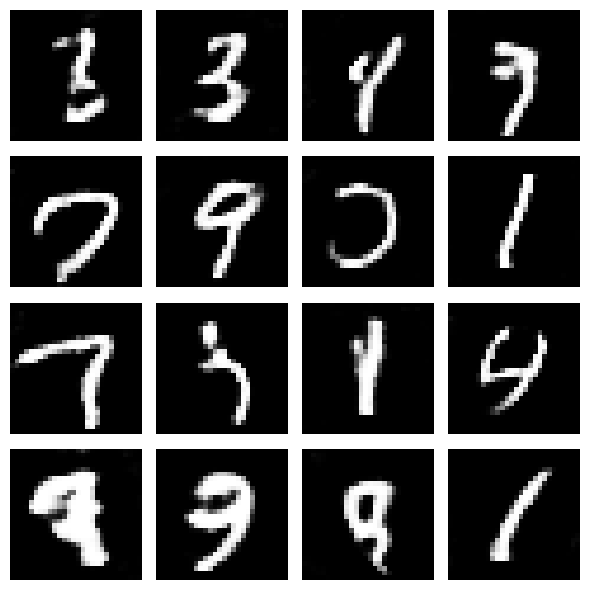

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

# 1. Load MNIST Dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize images to [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train.reshape(-1, 28, 28, 1)

print("Dataset Shape:", x_train.shape)

# 2. Create Generator
generator = tf.keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(7 * 7 * 128),
    layers.LeakyReLU(0.2),
    layers.Reshape((7, 7, 128)),

    layers.Conv2DTranspose(64, 4, strides=2, padding="same"),
    layers.LeakyReLU(0.2),

    layers.Conv2DTranspose(1, 4, strides=2,
                           padding="same",
                           activation="tanh")])

# 3. Create Discriminator
discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(64, 4, strides=2, padding="same"),
    layers.LeakyReLU(0.2),

    layers.Conv2D(128, 4, strides=2, padding="same"),
    layers.LeakyReLU(0.2),

    layers.Flatten(),
    layers.Dense(1, activation="sigmoid")
])

# 4. Compile Discriminator
discriminator.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"])

# 5. Create GAN
discriminator.trainable = False
gan = tf.keras.Sequential([
    generator,
    discriminator
])
gan.compile(
    optimizer="adam",
    loss="binary_crossentropy")

# 6. Train GAN
batch_size = 128
epochs = 20
for epoch in range(epochs):
    d_losses = []
    g_losses = []

    for i in range(0, len(x_train), batch_size):

        # Get real images
        real_images = x_train[i:i + batch_size]
        current_batch = len(real_images)

        # Generate fake images
        noise = np.random.normal(0, 1, (current_batch, 100))
        fake_images = generator.predict(noise, verbose=0)

        # Train Discriminator
        discriminator.trainable = True
        real_labels = np.ones((current_batch, 1))
        fake_labels = np.zeros((current_batch, 1))
        d_loss_real = discriminator.train_on_batch(
            real_images, real_labels)
        d_loss_fake = discriminator.train_on_batch(
            fake_images, fake_labels)
        d_loss = (d_loss_real[0] + d_loss_fake[0]) / 2
        d_losses.append(d_loss)

        # Train Generator
        discriminator.trainable = False
        noise = np.random.normal(0, 1, (current_batch, 100))
        misleading_labels = np.ones((current_batch, 1))

        g_loss = gan.train_on_batch(
            noise, misleading_labels)
        g_losses.append(g_loss)

    # Display epoch results
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"D Loss: {np.mean(d_losses):.4f} | "
        f"G Loss: {np.mean(g_losses):.4f}")

# 7. Generate Synthetic Images
noise = np.random.normal(0, 1, (16, 100))
generated_images = generator.predict(noise, verbose=0)

# 8. Display Generated Images
plt.figure(figsize=(6, 6))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        generated_images[i].reshape(28, 28),
        cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()